
# BHARATH BUILDS
## 21 Days to ML Engineer

---

# Day 13 — Gradient Boosting + XGBoost

**Session Type:** Theory + Hands-on Practical  
**Domain:** Machine Learning — Supervised Learning  
**Task:** Binary Classification  
**Dataset:** Breast Cancer Wisconsin Dataset  
**Libraries:** Python, Pandas, Matplotlib, Scikit-learn, XGBoost

---

## 1. Session Overview

This session focuses on understanding Gradient Boosting and XGBoost, implementing boosted-tree models, tuning their hyperparameters, and comparing their performance against a Random Forest baseline.

The objective is to develop a reproducible model-selection workflow using cross-validation, appropriate evaluation metrics, and held-out test data.

## 2. Learning Objectives

By the end of this session, you will be able to:

- Explain how Gradient Boosting builds models sequentially using negative gradients.
- Understand the roles of `learning_rate` and `n_estimators`.
- Explain how XGBoost uses gradient information, regularization, and efficient tree construction.
- Understand important XGBoost parameters, including `max_depth`, `min_child_weight`, `gamma`, `reg_alpha`, `reg_lambda`, `subsample`, and `colsample_bytree`.
- Identify potential overfitting using training and validation performance.
- Apply cross-validation and hyperparameter tuning for model selection.
- Compare Random Forest, Gradient Boosting, and XGBoost using consistent evaluation metrics.
- Evaluate selected models on a held-out test set.
- Document and export experimental results for a GitHub portfolio.

## 3. Theoretical Concepts Covered

### Gradient Boosting

- Boosting intuition and sequential error correction
- Loss functions, gradients, and negative gradients
- Residuals in squared-error regression
- Additive model updates
- Learning rate and number of boosting stages
- Learning rate versus `n_estimators`

### XGBoost

- Overview and key improvements over standard Gradient Boosting
- First-order and second-order gradient information
- Objective function: prediction loss + regularization penalty
- Tree construction and split evaluation
- Native missing-value handling

### Regularization and Generalization

- `max_depth`
- `min_child_weight`
- `gamma`
- `reg_alpha` — L1 regularization
- `reg_lambda` — L2 regularization
- `subsample` and `colsample_bytree`
- Underfitting, overfitting, and good generalization
- Early stopping and validation-based model selection

### Model Evaluation

- Training versus validation performance
- Cross-validation and hyperparameter tuning
- Accuracy, precision, recall, F1-score, and ROC-AUC
- Model comparison and final test evaluation
- Avoiding test-set leakage during model selection

## 4. Practical Implementation Plan

The practical session follows this workflow:

1. Install and import the required libraries.
2. Load the Breast Cancer Wisconsin dataset.
3. Inspect the dataset shape, target labels, and class distribution.
4. Split the data into training and held-out test sets.
5. Configure stratified five-fold cross-validation.
6. Train and tune a Random Forest baseline.
7. Train and tune a Gradient Boosting classifier.
8. Train and tune an XGBoost classifier, if available.
9. Compare cross-validation training and validation ROC-AUC.
10. Visualize model comparison results.
11. Evaluate selected configurations on the held-out test set.
12. Inspect class-specific precision, recall, and F1-score.
13. Analyze the confusion matrix.
14. Export comparison tables as CSV files.
15. Interpret the results, document limitations, and complete the assignment.

## 5. Dataset Information

**Dataset:** Breast Cancer Wisconsin Dataset  
**Source:** Scikit-learn built-in dataset  
**Problem Type:** Binary Classification  
**Target Classes:** Malignant and Benign  
**Features:** Numerical measurements computed from digitized breast mass images.

The target encoding in this dataset is:

- `0` — Malignant
- `1` — Benign

**Evaluation consideration:** Precision and recall must be interpreted with the positive-class definition in mind. For cancer detection, malignant-class performance deserves specific attention.

## 6. Model Selection Strategy

The following models will be compared:

| Model | Purpose |
|---|---|
| Random Forest | Baseline comparison |
| Gradient Boosting | Sequential boosting approach |
| XGBoost | Optimized gradient-boosting implementation |

**Selection metric:** ROC-AUC  
**Validation strategy:** Stratified 5-fold cross-validation  
**Final evaluation:** Held-out test set

Hyperparameters will be selected using training data and cross-validation. The test set will remain separate from tuning decisions.

## 7. Expected Deliverables

By the end of this practical session, the experiment should produce:

- Best hyperparameters for each available model
- Cross-validation comparison table
- Training-versus-validation performance analysis
- Model comparison visualization
- Final test-set evaluation metrics
- Classification reports and confusion matrix
- Exported CSV result files
- Documented conclusions and limitations
- Reproducible notebook ready for GitHub

## 8. Engineering Workflow

**Understand → Implement → Evaluate → Compare → Interpret → Document → Commit**

The goal is not simply to obtain the highest score. It is to understand model behavior, evaluate generalization, compare alternatives fairly, and document a reproducible machine learning experiment.

---

**Bharath Builds | Day 13 — Gradient Boosting + XGBoost**


step1 : install XGBOOST

In [1]:
%pip install xgboost

step 2 : install required libraries

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42

step 3: load the dataset

In [5]:
data=load_breast_cancer(as_frame=True)
X=data.data
y=data.target

print("feature matrix shape:",X.shape)
print("target vector shape:",y.shape)

print("\\nclass count:")
print(y.map({0:"malignant",1:"benign"}).value_counts())

feature matrix shape: (569, 30)
target vector shape: (569,)
\nclass count:
target
benign       357
malignant    212
Name: count, dtype: int64


In [9]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [10]:
X.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


step 4: spliting dataset

In [12]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=RANDOM_STATE,stratify=y)

print("train set shape:",X_train.shape)
print("test set shape:",X_test.shape)
print("training class proportions")
print(y_train.value_counts(normalize=True))
print("test class proportion")
print(y_test.value_counts(normalize=True))

train set shape: (455, 30)
test set shape: (114, 30)
training class proportions
target
1    0.626374
0    0.373626
Name: proportion, dtype: float64
test class proportion
target
1    0.631579
0    0.368421
Name: proportion, dtype: float64


step 5: k fold cross validation

In [13]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)

step 6: train random forest baseline

In [15]:
rf_grid=GridSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE,n_jobs=-1),
    param_grid={
        "n_estimators":[10,50,100,200],
        "max_depth":[None,5,10,15]
    },
    scoring="roc_auc",
    cv=cv,
    verbose=1,
    return_train_score=True
)


rf_grid.fit(X_train,y_train)
rf_best=rf_grid.best_estimator_

print("best hyperparameters:",rf_grid.best_params_)
print("best cross-validation score:",rf_grid.best_score_)

print("Mean training-fold AUC:", round(
    rf_grid.cv_results_["mean_train_score"][rf_grid.best_index_], 4
))
print("Mean validation CV AUC:", round(rf_grid.best_score_, 4))

Fitting 5 folds for each of 16 candidates, totalling 80 fits
best hyperparameters: {'max_depth': 5, 'n_estimators': 50}
best cross-validation score: 0.991124871001032
Mean training-fold AUC: 0.9997
Mean validation CV AUC: 0.9911


step 7: train and fine tune gradient boosting

In [21]:
model_grids = {
    "Random Forest": rf_grid,
    "Gradient Boosting": gb_grid
}

try:
    from xgboost import XGBClassifier

    xgb_grid = GridSearchCV(
        estimator=XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=1
        ),
        param_grid={
            "n_estimators": [100, 200],
            "learning_rate": [0.05, 0.1],
            "max_depth": [3, 5],
            "subsample": [0.8, 1.0]
        },
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        return_train_score=True
    )

    xgb_grid.fit(X_train, y_train)
    model_grids["XGBoost"] = xgb_grid
    print("Best XGBoost parameters:", xgb_grid.best_params_)
    print("Mean validation CV AUC:", round(xgb_grid.best_score_, 4))

except Exception as exc:
    print("XGBoost could not be used in this runtime:", exc)
    print("Continuing with Random Forest and Gradient Boosting.")

Best XGBoost parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'subsample': 0.8}
Mean validation CV AUC: 0.9943


Step 9 — Compare Training and Validation Behavior

In [22]:
rows = []

for name, search in model_grids.items():
    idx = search.best_index_
    rows.append({
        "Model": name,
        "Mean Training CV AUC": search.cv_results_["mean_train_score"][idx],
        "Mean Validation CV AUC": search.best_score_,
        "CV Gap (Train - Validation)": (
            search.cv_results_["mean_train_score"][idx] - search.best_score_
        ),
        "Best Parameters": str(search.best_params_)
    })

cv_comparison = pd.DataFrame(rows).sort_values(
    "Mean Validation CV AUC", ascending=False
)

display(cv_comparison.round(4))

,Model,Mean Training CV AUC,Mean Validation CV AUC,CV Gap (Train - Validation),Best Parameters
2,XGBoost,1.0000,0.9943,0.0057,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti..."
1,Gradient Boosting,1.0000,0.9929,0.0071,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti..."
0,Random Forest,0.9997,0.9911,0.0086,"{'max_depth': 5, 'n_estimators': 50}"


Step 10 — Visualize Validation AUC

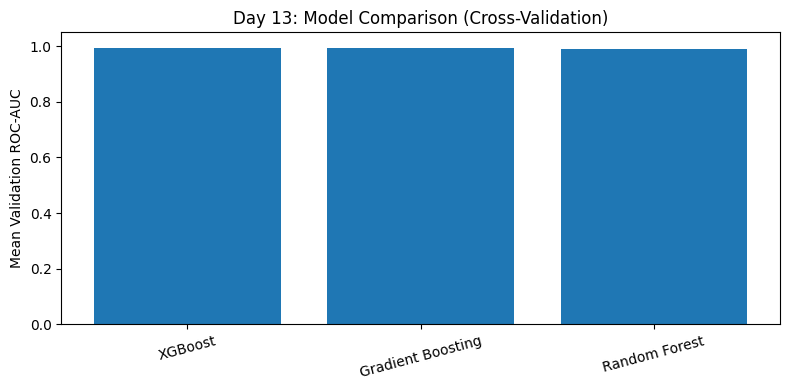

In [23]:
plt.figure(figsize=(8, 4))
plt.bar(
    cv_comparison["Model"],
    cv_comparison["Mean Validation CV AUC"]
)
plt.ylabel("Mean Validation ROC-AUC")
plt.title("Day 13: Model Comparison (Cross-Validation)")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Step 11 — Final Evaluation on the Held-Out Test Set

In [24]:
test_rows = []

for name, search in model_grids.items():
    model = search.best_estimator_
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    test_rows.append({
        "Model": name,
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Precision (benign=1)": precision_score(y_test, y_pred, pos_label=1),
        "Test Recall (benign=1)": recall_score(y_test, y_pred, pos_label=1),
        "Test F1 (benign=1)": f1_score(y_test, y_pred, pos_label=1),
        "Test ROC-AUC": roc_auc_score(y_test, y_prob)
    })

test_comparison = pd.DataFrame(test_rows).sort_values(
    "Test ROC-AUC", ascending=False
)
display(test_comparison.round(4))

,Model,Test Accuracy,Test Precision (benign=1),Test Recall (benign=1),Test F1 (benign=1),Test ROC-AUC
0,Random Forest,0.9561,0.9589,0.9722,0.9655,0.9937
2,XGBoost,0.9561,0.9467,0.9861,0.9660,0.9931
1,Gradient Boosting,0.9474,0.9459,0.9722,0.9589,0.9914


Step 12 — Inspect Class-Specific Performance

In [25]:
for name, search in model_grids.items():
    print("\n" + "=" * 60)
    print(name)
    print(classification_report(
        y_test,
        search.best_estimator_.predict(X_test),
        target_names=["malignant (0)", "benign (1)"],
        digits=3
    ))


Random Forest
               precision    recall  f1-score   support

malignant (0)      0.951     0.929     0.940        42
   benign (1)      0.959     0.972     0.966        72

     accuracy                          0.956       114
    macro avg      0.955     0.950     0.953       114
 weighted avg      0.956     0.956     0.956       114


Gradient Boosting
               precision    recall  f1-score   support

malignant (0)      0.950     0.905     0.927        42
   benign (1)      0.946     0.972     0.959        72

     accuracy                          0.947       114
    macro avg      0.948     0.938     0.943       114
 weighted avg      0.947     0.947     0.947       114


XGBoost
               precision    recall  f1-score   support

malignant (0)      0.974     0.905     0.938        42
   benign (1)      0.947     0.986     0.966        72

     accuracy                          0.956       114
    macro avg      0.961     0.945     0.952       114
 weighted avg 

Step 13 — Plot the Confusion Matrix for the Best CV Model

Highest validation CV AUC model: XGBoost


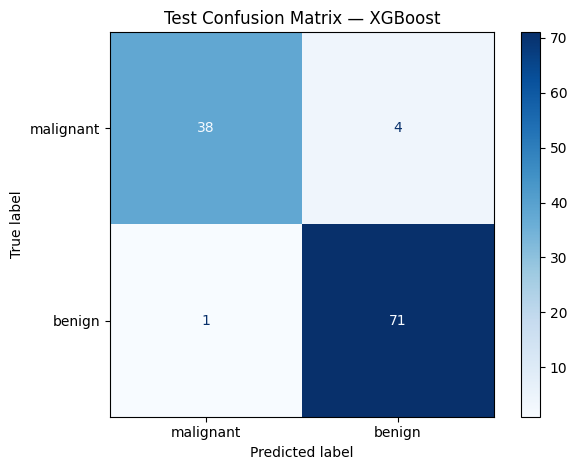

In [26]:
best_name = cv_comparison.iloc[0]["Model"]
best_model = model_grids[best_name].best_estimator_

print("Highest validation CV AUC model:", best_name)
ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    display_labels=["malignant", "benign"],
    cmap="Blues"
)
plt.title(f"Test Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

step 15: save the results and download the Result Files from Colab

In [28]:
cv_comparison.to_csv("day13_cv_comparison.csv", index=False)
test_comparison.to_csv("day13_test_comparison.csv", index=False)

print("Saved:")
print("- day13_cv_comparison.csv")
print("- day13_test_comparison.csv")

Saved:
- day13_cv_comparison.csv
- day13_test_comparison.csv


In [29]:
from google.colab import files

files.download("day13_cv_comparison.csv")
files.download("day13_test_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Step 16 — Final Interpretation and Assignment

Random Forest achieved 95.61% accuracy and performed consistently.



XGBoost also achieved 95.61% accuracy, with the highest ROC-AUC of 0.9660.



Gradient Boosting achieved 94.74% accuracy, slightly lower than the other two models.



XGBoost achieved 98.6% recall for benign cases.



Random Forest achieved 92.9% recall for malignant cases, slightly better than the 90.5% achieved by both boosting models.



XGBoost had the highest malignant precision at 97.4%.



Random Forest and XGBoost showed the strongest overall test performance.



Key takeaway: No single model wins every metric; the best choice depends on the problem's priorities.